# Hello World Agent

이 예제는 A2A(에이전트 간 통신) 파이썬 SDK를 사용하여 기본적인 A2A 서버 및 클라이언트 구현을 보여줍니다.

https://github.com/a2aproject/a2a-samples/tree/main/samples/python/agents/helloworld


# 세팅

In [13]:
from dotenv import load_dotenv

load_dotenv()

True

In [33]:
!  pip install -U "a2a-sdk" 


[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: C:\Users\jino7\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [29]:
! uv pip install --upgrade "protobuf>=5.29,<7"

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Resolved 1 package in 30ms
Audited 1 package in 0.54ms


# A2A 서버 실행

## 서버 코드

In [ ]:
# a2a_hello_world_server.py
# 실행: python a2a_hello_world_server.py

import uvicorn

from a2a.helpers import (
    get_message_text,
    new_task_from_user_message,
    new_text_message,
    new_text_part,
)
from a2a.server.agent_execution import AgentExecutor, RequestContext
from a2a.server.events import EventQueue
from a2a.server.request_handlers import DefaultRequestHandler
from a2a.server.routes import (
    create_agent_card_routes,
    create_jsonrpc_routes,
)
from a2a.server.tasks import InMemoryTaskStore, TaskUpdater
from a2a.types import (
    AgentCapabilities,
    AgentCard,
    AgentInterface,
    AgentSkill,
    TaskState,
)
from starlette.applications import Starlette


class HelloWorldAgent:
    """Hello World 에이전트."""

    async def invoke(self, user_request: str) -> str:
        """전달받은 사용자 요청 문자열을 그대로 포함한 인사 응답을 생성한다."""
        return f'Hello, World! I have received your request ({user_request})'


class HelloWorldAgentExecutor(AgentExecutor):
    """A2A 서버가 요청을 처리할 때 호출하는 실행기 구현."""

    def __init__(self) -> None:
        # 실제 응답 생성을 담당하는 에이전트 인스턴스를 보유
        self.agent = HelloWorldAgent()

    async def execute(
        self,
        context: RequestContext,
        event_queue: EventQueue,
    ) -> None:
        """사용자 요청을 처리한다."""
        # 1. 요청 컨텍스트에서 태스크를 수집
        if context.current_task:
            task = context.current_task
        else:
            # 1.1 태스크가 없으면 사용자 메시지로부터 새로 생성해 이벤트 큐에 추가
            task = new_task_from_user_message(context.message)
            await event_queue.enqueue_event(task)

        # 2. TaskUpdater 객체를 사용해 이벤트 큐의 태스크 상태를 갱신
        task_updater = TaskUpdater(
            event_queue=event_queue, task_id=task.id, context_id=task.context_id
        )
        await task_updater.update_status(
            state=TaskState.TASK_STATE_WORKING,
            message=new_text_message('Processing request...'),
        )

        # 3. 요청 내용에서 사용자 질의를 추출하고 에이전트를 호출해 응답을 생성
        query = get_message_text(context.message)
        if query:
            result = await self.agent.invoke(user_request=query)
        else:
            result = 'No text input is provided!'

        # 4. 생성된 응답을 아티팩트로 이벤트 큐에 추가
        await task_updater.add_artifact(
            parts=[new_text_part(text=result, media_type='text/plain')]
        )
        print('Result: ', result)

        # 5. 태스크 상태를 완료로 갱신
        await task_updater.update_status(
            state=TaskState.TASK_STATE_COMPLETED,
            message=new_text_message('Request is completed!'),
        )

    async def cancel(self, context: RequestContext, event_queue: EventQueue) -> None:
        """취소를 지원하지 않으므로 예외를 발생시킨다."""
        raise NotImplementedError('Cancel is not supported.')


if __name__ == '__main__':
    # 에이전트가 수행할 수 있는 기능을 정의
    skill = AgentSkill(
        id='echo_bot',
        name='Echo Bot',
        description='An example agent that acknowledges client request and responds with a "Hello World" message.',
        input_modes=['text/plain'],
        output_modes=['text/plain'],
        tags=['a2a', 'echo-example'],
        examples=['hi', 'how are you'],
    )

    # 공개 카드에는 노출되지 않는 추가 스킬을 정의
    extended_skill = AgentSkill(
        id='echo_bot_super_mode',
        name='Echo Bot (Super Mode)',
        description='An extended version of Echo Bot that responds with extra enthusiasm!',
        tags=['a2a', 'echo-example', 'extended'],
        examples=['super hi', 'give me a super hello'],
    )

    # 클라이언트가 에이전트의 기능을 탐색할 수 있도록 공개용 에이전트 카드를 정의
    public_agent_card = AgentCard(
        # A2A 서버의 기본 신원 정보
        name='Hello World Agent',
        description='Just a hello world agent',
        version='0.0.1',
        # 에이전트 상호작용의 기본 미디어 타입
        default_input_modes=['text/plain'],
        default_output_modes=['text/plain'],
        # 지원하는 A2A 기능(스트리밍, 확장 카드 등)
        capabilities=AgentCapabilities(streaming=True, extended_agent_card=True),
        # 서비스에 접근 가능한 엔드포인트와 프로토콜의 순서 있는 목록
        supported_interfaces=[
            AgentInterface(
                protocol_binding='JSONRPC',
                url='http://127.0.0.1:9999',
                protocol_version='1.0',
            )
        ],
        # 이 에이전트가 제공하는 AgentSkill 객체 목록
        skills=[skill],
        # 선택 속성(여기서는 생략): icon_url -> 에이전트를 나타내는 아이콘 URL
    )

    # 인증된 사용자에게만 보이는 확장 스킬을 포함한 확장 에이전트 카드를 정의
    extended_agent_card = AgentCard(
        name='Hello World Agent - Extended Edition',
        description='The full-featured hello world agent for authenticated users.',
        version='0.0.2',
        default_input_modes=['text/plain'],
        default_output_modes=['text/plain'],
        capabilities=AgentCapabilities(streaming=True, extended_agent_card=True),
        supported_interfaces=[
            AgentInterface(
                protocol_binding='JSONRPC',
                url='http://127.0.0.1:9999',
                protocol_version='1.0',
            )
        ],
        # 확장 카드에는 두 스킬을 모두 포함
        skills=[
            skill,
            extended_skill,
        ],
    )

    # RequestHandler는 들어오는 요청을 처리하고 태스크를 관리
    request_handler = DefaultRequestHandler(
        # 클라이언트 요청의 실행을 담당하는 에이전트 실행기
        agent_executor=HelloWorldAgentExecutor(),
        # 태스크를 저장하고 관리하는 저장소
        task_store=InMemoryTaskStore(),
        # 비인증 사용자를 위한 공개 에이전트 카드
        agent_card=public_agent_card,
        # 인증 사용자를 위한 확장 에이전트 카드
        extended_agent_card=extended_agent_card,
    )

    # A2A 서버의 라우트를 생성
    # 클라이언트로부터의 요청과 클라이언트로의 응답을 처리
    routes = []

    # 에이전트 카드용 라우트를 생성
    routes.extend(create_agent_card_routes(public_agent_card))

    # JSONRPC 프로토콜용 라우트를 생성
    # 요구사항에 따라 GRPC 또는 HTTP_JSON 프로토콜 바인딩을 선택할 수도 있음
    routes.extend(create_jsonrpc_routes(request_handler, '/'))

    # 정의된 라우트로 웹 앱을 생성
    # 여기서는 경량 ASGI 웹 프레임워크인 Starlette를 사용
    # FastAPI 등 다른 ASGI 프레임워크를 선택할 수도 있음
    app = Starlette(routes=routes)

    # 앱을 실행
    # Uvicorn은 프로덕션 환경에서 사용 가능한 ASGI HTTP 서버
    uvicorn.run(app, host='127.0.0.1', port=9999)

터미날에서 실행

uv pip install --upgrade "protobuf>=5.29,<7"

In [ ]:
 python helloserver.py 

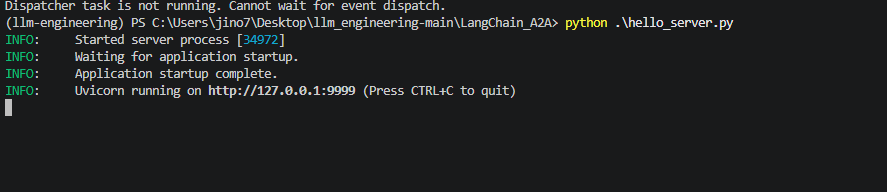

# A2A 클라이언트 구축

In [1]:
# [셀 1] 임포트 및 설정
import httpx

from a2a.client import A2ACardResolver, ClientConfig, create_client
from a2a.helpers import display_agent_card, new_text_message
from a2a.types import GetExtendedAgentCardRequest, Role, SendMessageRequest

# A2A 서버의 베이스 URL (에이전트 카드는 기본 경로 /.well-known/agent-card.json 에서 조회됨)
BASE_URL = 'http://127.0.0.1:9999'

# 이후 셀에서 재사용할 질의 문자열
TEXT_QUERY = 'Hi there!'

In [2]:
# [셀 2] 공개 에이전트 카드 조회
# A2ACardResolver가 사용할 HTTP 클라이언트를 생성
async with httpx.AsyncClient() as httpx_client:
    # HTTP 클라이언트와 베이스 URL로 리졸버를 초기화하고 기본 카드 경로를 사용
    resolver = A2ACardResolver(
        httpx_client=httpx_client,
        base_url=BASE_URL,
        # 에이전트가 다른 경로를 사용한다면 agent_card_path 인자를 지정
        # agent_card_path='',
    )
    # 서버에서 공개 에이전트 카드를 가져옴
    public_agent_card = await resolver.get_agent_card()

# 카드 내용을 사람이 읽기 좋은 형태로 출력
display_agent_card(public_agent_card)

                     AgentCard                      
--- General ---
Name        : Hello World Agent
Description : Just a hello world agent
Version     : 0.0.1

--- Interfaces ---
  [0] http://127.0.0.1:9999  (JSONRPC 1.0)

--- Capabilities ---
Streaming           : True
Push notifications  : False
Extended agent card : True

--- I/O Modes ---
Input  : text/plain
Output : text/plain

--- Skills ---
----------------------------------------------------
  ID          : echo_bot
  Name        : Echo Bot
  Description : An example agent that acknowledges client request and responds with a "Hello World" message.
  Tags        : a2a, echo-example
  Example     : hi
  Example     : how are you


In [3]:
# [셀 3] 비스트리밍 방식으로 메시지 전송
# 스트리밍을 끈 설정으로 카드에 맞는 transport 클라이언트를 생성
config = ClientConfig(streaming=False)
client = await create_client(agent=public_agent_card, client_config=config)

# 사용자 역할의 텍스트 메시지를 만들고 요청 객체로 감쌈
message = new_text_message(TEXT_QUERY, role=Role.ROLE_USER)
request = SendMessageRequest(message=message)

# 응답 청크를 순회하며 그대로 출력
async for chunk in client.send_message(request):
    print(chunk)

# 클라이언트가 점유한 전송 자원을 해제
await client.close()

task {
  id: "312971d8-3e61-4fcc-9823-18596a3d02ae"
  context_id: "13aa1931-3b1e-47b5-8593-8b4d3672cb6c"
  status {
    state: TASK_STATE_COMPLETED
    message {
      message_id: "f30d4bd1-26bb-498a-8f7e-f9d0771e2186"
      role: ROLE_AGENT
      parts {
        text: "Request is completed!"
      }
    }
    timestamp {
      seconds: 1787625665
      nanos: 514214000
    }
  }
  artifacts {
    artifact_id: "f844a14f-092d-4061-b179-3da74031199b"
    parts {
      text: "Hello, World! I have received your request (Hi there!)"
      media_type: "text/plain"
    }
  }
  history {
    message_id: "14de58b8-3a06-40ec-a02b-7f6982c3d33e"
    context_id: "13aa1931-3b1e-47b5-8593-8b4d3672cb6c"
    task_id: "312971d8-3e61-4fcc-9823-18596a3d02ae"
    role: ROLE_USER
    parts {
      text: "Hi there!"
    }
  }
  history {
    message_id: "d7b251d0-2aa0-4e45-a51d-86c70fd1ec66"
    role: ROLE_AGENT
    parts {
      text: "Processing request..."
    }
  }
}



In [4]:
# [셀 4] 스트리밍 방식으로 메시지 전송
# 스트리밍을 켠 설정으로 클라이언트를 생성
client_config = ClientConfig(streaming=True)
client = await create_client(agent=public_agent_card, client_config=client_config)

# 사용자 역할의 텍스트 메시지를 만들고 요청 객체로 감쌈
message = new_text_message(TEXT_QUERY, role=Role.ROLE_USER)
request = SendMessageRequest(message=message)

# 서버가 보내오는 중간 이벤트까지 순차적으로 출력
async for chunk in client.send_message(request):
    print(chunk)

# 클라이언트가 점유한 전송 자원을 해제
await client.close()

task {
  id: "f0585b64-0851-4d4a-ace1-1f989947f28d"
  context_id: "feededab-a68f-45a1-99d1-c0fc3fafa0ad"
  status {
    state: TASK_STATE_SUBMITTED
  }
  history {
    message_id: "7c9c2575-a610-47f3-9815-a17e32248049"
    context_id: "feededab-a68f-45a1-99d1-c0fc3fafa0ad"
    task_id: "f0585b64-0851-4d4a-ace1-1f989947f28d"
    role: ROLE_USER
    parts {
      text: "Hi there!"
    }
  }
}

status_update {
  task_id: "f0585b64-0851-4d4a-ace1-1f989947f28d"
  context_id: "feededab-a68f-45a1-99d1-c0fc3fafa0ad"
  status {
    state: TASK_STATE_WORKING
    message {
      message_id: "c9306a58-3a6a-4e01-8832-aeb783270dcb"
      role: ROLE_AGENT
      parts {
        text: "Processing request..."
      }
    }
    timestamp {
      seconds: 1787625670
      nanos: 647249000
    }
  }
}

artifact_update {
  task_id: "f0585b64-0851-4d4a-ace1-1f989947f28d"
  context_id: "feededab-a68f-45a1-99d1-c0fc3fafa0ad"
  artifact {
    artifact_id: "c9702ae8-c366-4942-8829-9f1256976316"
    parts {
     

In [6]:
# [셀 5] 인증된 확장 에이전트 카드 조회
# 확장 카드 조회는 단발성 요청이므로 비스트리밍 설정으로 클라이언트를 생성
config = ClientConfig(streaming=False)
client = await create_client(agent=public_agent_card, client_config=config)

# 공개 카드에 노출되지 않는 스킬까지 포함된 확장 카드를 요청
extended_card = await client.get_extended_agent_card(GetExtendedAgentCardRequest())
display_agent_card(extended_card)

# 클라이언트가 점유한 전송 자원을 해제
await client.close()

                     AgentCard                      
--- General ---
Name        : Hello World Agent - Extended Edition
Description : The full-featured hello world agent for authenticated users.
Version     : 0.0.2

--- Interfaces ---
  [0] http://127.0.0.1:9999  (JSONRPC 1.0)

--- Capabilities ---
Streaming           : True
Push notifications  : False
Extended agent card : True

--- I/O Modes ---
Input  : text/plain
Output : text/plain

--- Skills ---
----------------------------------------------------
  ID          : echo_bot
  Name        : Echo Bot
  Description : An example agent that acknowledges client request and responds with a "Hello World" message.
  Tags        : a2a, echo-example
  Example     : hi
  Example     : how are you
----------------------------------------------------
  ID          : echo_bot_super_mode
  Name        : Echo Bot (Super Mode)
  Description : An extended version of Echo Bot that responds with extra enthusiasm!
  Tags        : a2a, echo-example, ext

---

최소 코드

In [29]:
import httpx

from a2a.client import A2ACardResolver, create_client
from a2a.helpers import new_text_message
from a2a.types import Role, SendMessageRequest

BASE_URL = 'http://127.0.0.1:9999'

# 서버에서 에이전트 카드를 가져옴 (접속에 필요한 endpoint·프로토콜 정보가 들어있음)
async with httpx.AsyncClient() as httpx_client:
    card = await A2ACardResolver(httpx_client=httpx_client, base_url=BASE_URL).get_agent_card()

# 카드 정보를 바탕으로 통신 클라이언트 생성
client = await create_client(agent=card)

# 사용자 역할 텍스트 메시지를 만들어 전송하고 응답을 출력
request = SendMessageRequest(message=new_text_message('Hi there!', role=Role.ROLE_USER))
async for chunk in client.send_message(request):
    print(chunk)

await client.close()

task {
  id: "d7f05fa8-1a96-43b8-aa3d-95bf958cf313"
  context_id: "ea1b1840-7cff-4e2b-9a1c-772f1fedc320"
  status {
    state: TASK_STATE_SUBMITTED
  }
  history {
    message_id: "2c506d02-6770-4097-9ed7-dc7555ac6280"
    context_id: "ea1b1840-7cff-4e2b-9a1c-772f1fedc320"
    task_id: "d7f05fa8-1a96-43b8-aa3d-95bf958cf313"
    role: ROLE_USER
    parts {
      text: "Hi there!"
    }
  }
}

artifact_update {
  task_id: "d7f05fa8-1a96-43b8-aa3d-95bf958cf313"
  context_id: "ea1b1840-7cff-4e2b-9a1c-772f1fedc320"
  artifact {
    artifact_id: "4e7020cf-2136-464c-8010-3137fac4203e"
    parts {
      text: "Hello, World! (Hi there!)"
      media_type: "text/plain"
    }
  }
}

status_update {
  task_id: "d7f05fa8-1a96-43b8-aa3d-95bf958cf313"
  context_id: "ea1b1840-7cff-4e2b-9a1c-772f1fedc320"
  status {
    state: TASK_STATE_COMPLETED
    timestamp {
      seconds: 1784801771
      nanos: 669660000
    }
  }
}



# A2A 서버 LangCahin agent 연결

In [14]:
# [셀 2] 임포트 및 설정
from typing import Any

import httpx
from a2a.client import ClientConfig, create_client
from a2a.helpers import get_stream_response_text, new_text_message
from a2a.types import Role, SendMessageRequest

from langchain.agents import create_agent
from langchain.tools import tool
from langchain_openai import ChatOpenAI

# A2A 서버의 베이스 URL (에이전트 카드는 기본 경로 /.well-known/agent-card.json 에서 조회됨)
A2A_BASE_URL = "http://localhost:9999"

In [15]:
# [셀 3] A2A 서버 호출을 LangChain 툴로 래핑
@tool
async def hello_world_agent(query: str) -> str:
    """원격 A2A 인사 에이전트에게 메시지를 보내고 응답 텍스트를 받아온다. 인사 요청 시 사용한다."""
    # 툴 호출 1회 동안만 유지되는 HTTP 클라이언트를 생성
    async with httpx.AsyncClient(timeout=30.0) as http_client:
        # A2A_BASE_URL의 AgentCard를 조회해 그에 맞는 transport로 클라이언트를 생성
        client = await create_client(
            agent=A2A_BASE_URL,
            client_config=ClientConfig(streaming=False, httpx_client=http_client),
        )
        # 텍스트 단일 Part를 가진 사용자 메시지를 생성해 요청으로 감쌈
        request = SendMessageRequest(message=new_text_message(query, role=Role.ROLE_USER))
        # StreamResponse를 순회하며 텍스트만 추출
        texts = [get_stream_response_text(r) async for r in client.send_message(request)]
    # 빈 문자열을 제외하고 줄바꿈으로 연결해 반환
    return "\n".join(filter(None, texts))

In [16]:
# [셀 5] 툴 단독 동작 확인 (에이전트 없이 A2A 연결만 검증)
# 셀에서 await를 직접 사용
print(await hello_world_agent.ainvoke({"query": "안녕하세요"}))

Hello, World! (안녕하세요)


In [17]:
# [셀 6] LangChain 에이전트 구성
llm = ChatOpenAI(model="gpt-5-mini", temperature=0)

agent = create_agent(
    model=llm,
    tools=[hello_world_agent],
    system_prompt=(
        "너는 사용자의 요청을 처리하는 에이전트다. "
        "인사말이 필요한 요청은 hello_world_agent 툴을 호출해 원격 A2A 에이전트의 응답을 받아 전달해라."
    ),
)

In [11]:
# [셀 7] 에이전트 실행
result = await agent.ainvoke(
    {"messages": [{"role": "user", "content": "원격 에이전트한테 인사 좀 시켜줘"}]}
)

# 마지막 메시지가 최종 응답
print(result["messages"][-1].content)

원격 에이전트가 응답했습니다: Hello, World! I have received your request (사용자가 인사해 달라고 요청했습니다. 간단한 한국어 인사말을 해 주세요.)


In [12]:
# [셀 8] 스트리밍 출력으로 중간 단계 확인 (선택)
async for step in agent.astream(
    {"messages": [{"role": "user", "content": "인사해줘"}]},
    stream_mode="values",
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

인사해줘
================================== Ai Message ==================================
Tool Calls:
  hello_world_agent (call_ePq5XL7fgOFiCPArdRIznn4w)
 Call ID: call_ePq5XL7fgOFiCPArdRIznn4w
  Args:
    query: 인사해줘
================================= Tool Message =================================
Name: hello_world_agent

Hello, World! I have received your request (인사해줘)
================================== Ai Message ==================================

Hello, World! I have received your request (인사해줘)
